# LAB 06 — ATTENTION MECHANISM

**Môn học**: Xử lý ngôn ngữ tự nhiên và ứng dụng  
**Học kỳ**: Học kỳ I - 2026  
**Chủ đề**: From Recurrent State to Context-Aware Representation  

Notebook này thực thi toàn bộ các thí nghiệm về cơ chế Attention:
1. Triển khai scaled dot-product attention và softmax ổn định số học bằng NumPy.
2. Khảo sát ảnh hưởng của scaling factor và hệ số nhiệt độ (temperature).
3. Phân tích phân phối attention weights theo query và quan sát sự dịch chuyển trọng số.
4. Trực quan hóa ma trận Attention (Heatmap) trên các câu có cấu trúc ngữ nghĩa rõ.
5. Ứng dụng mô hình Self-Attention Classifier vào bài toán phân loại cảm xúc IMDb và đối chiếu với LSTM.
6. Đánh giá chi phí tính toán và bộ nhớ theo chiều dài chuỗi.

## 1. Thiết lập môi trường và nạp các thư viện

In [1]:
import os
import re
import time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from attention_numpy import stable_softmax, scaled_dot_product_attention

torch.manual_seed(42)
np.random.seed(42)

## 2. Kiểm tra tính ổn định số học của Softmax và Scaling

In [2]:
large_scores = np.array([1000.0, 1001.0, 1002.0])
stable_probs = stable_softmax(large_scores)
print("Stable Softmax output:", stable_probs)
print("Sum of probabilities:", np.sum(stable_probs))

scores_demo = np.array([4.0, 2.0, 0.0])
unscaled_weights = stable_softmax(scores_demo)
scaled_weights = stable_softmax(scores_demo / np.sqrt(4.0))

scaling_df = pd.DataFrame({
    'Element': ['Score 1 (4.0)', 'Score 2 (2.0)', 'Score 3 (0.0)'],
    'Unscaled_Weight': unscaled_weights,
    'Scaled_Weight': scaled_weights
})
print("\nComparison of Scaling Effect:")
print(scaling_df)

Stable Softmax output: [0.09003057 0.24472847 0.66524096]
Sum of probabilities: 0.9999999999999999

Comparison of Scaling Effect:
         Element  Unscaled_Weight  Scaled_Weight
0  Score 1 (4.0)         0.866813       0.665241
1  Score 2 (2.0)         0.117310       0.244728
2  Score 3 (0.0)         0.015876       0.090031


## 3. Khảo sát hệ số nhiệt độ (Temperature) trong Softmax

In [3]:
score_vector = np.array([2.0, 1.0, 0.0])
temperatures = [0.5, 1.0, 2.0]
records = []

for temp in temperatures:
    probs = stable_softmax(score_vector / temp)
    max_weight = np.max(probs)
    entropy = -np.sum(probs * np.log(probs + 1e-12))
    records.append({
        'Temperature': temp,
        'Weights': np.round(probs, 4).tolist(),
        'Max_Weight': round(float(max_weight), 4),
        'Entropy': round(float(entropy), 4)
    })

temp_df = pd.DataFrame(records)
print("Temperature Experiment Results:")
print(temp_df)

Temperature Experiment Results:
   Temperature                   Weights  Max_Weight  Entropy
0          0.5  [0.8668, 0.1173, 0.0159]      0.8668   0.4411
1          1.0    [0.6652, 0.2447, 0.09]      0.6652   0.8324
2          2.0  [0.5065, 0.3072, 0.1863]      0.5065   1.0202


## 4. Experiment 1: Phân phối Attention trên câu đơn

Experiment 1 Attention Distribution:
          Token  Score  Attention_Weight
0           the   -2.0            0.0023
1         movie    1.2            0.0552
2           was   -1.2            0.0050
3  surprisingly    2.8            0.2736
4          good    3.5            0.5509
5       despite    1.0            0.0452
6             a   -2.0            0.0023
7          very    0.8            0.0370
8          slow   -0.5            0.0101
9     beginning    0.1            0.0184


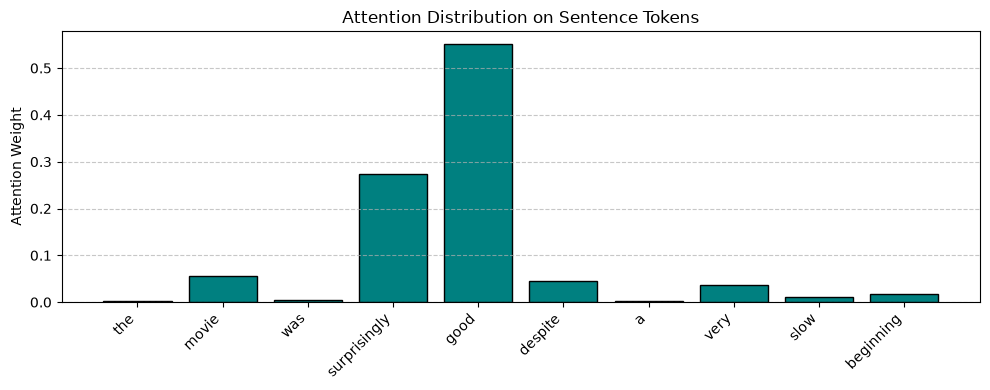

In [4]:
sentence = "The movie was surprisingly good despite a very slow beginning."
tokens = re.findall(r'\b\w+\b', sentence.lower())

word_scores = {
    'good': 3.5,
    'surprisingly': 2.8,
    'movie': 1.2,
    'slow': -0.5,
    'beginning': 0.1,
    'despite': 1.0,
    'was': -1.2,
    'the': -2.0,
    'a': -2.0,
    'very': 0.8
}

scores_list = np.array([word_scores.get(t, 0.0) for t in tokens])
weights_exp1 = stable_softmax(scores_list)

exp1_df = pd.DataFrame({
    'Token': tokens,
    'Score': scores_list,
    'Attention_Weight': np.round(weights_exp1, 4)
})
print("Experiment 1 Attention Distribution:")
print(exp1_df)

plt.figure(figsize=(10, 4))
plt.bar(range(len(tokens)), weights_exp1, color='teal', edgecolor='black')
plt.xticks(range(len(tokens)), tokens, rotation=45, ha='right')
plt.ylabel('Attention Weight')
plt.title('Attention Distribution on Sentence Tokens')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 5. Experiment 2: Sự dịch chuyển Attention khi thay đổi Query

Comparison Between Query A (Sentiment) and Query B (Topic):
          Token  Weight_Query_Sentiment  Weight_Query_Topic
0           the                  0.0023              0.0049
1         movie                  0.0552              0.5924
2           was                  0.0050              0.0049
3  surprisingly                  0.2736              0.0162
4          good                  0.5509              0.0218
5       despite                  0.0452              0.0162
6             a                  0.0023              0.0049
7          very                  0.0370              0.0133
8          slow                  0.0101              0.0594
9     beginning                  0.0184              0.2662


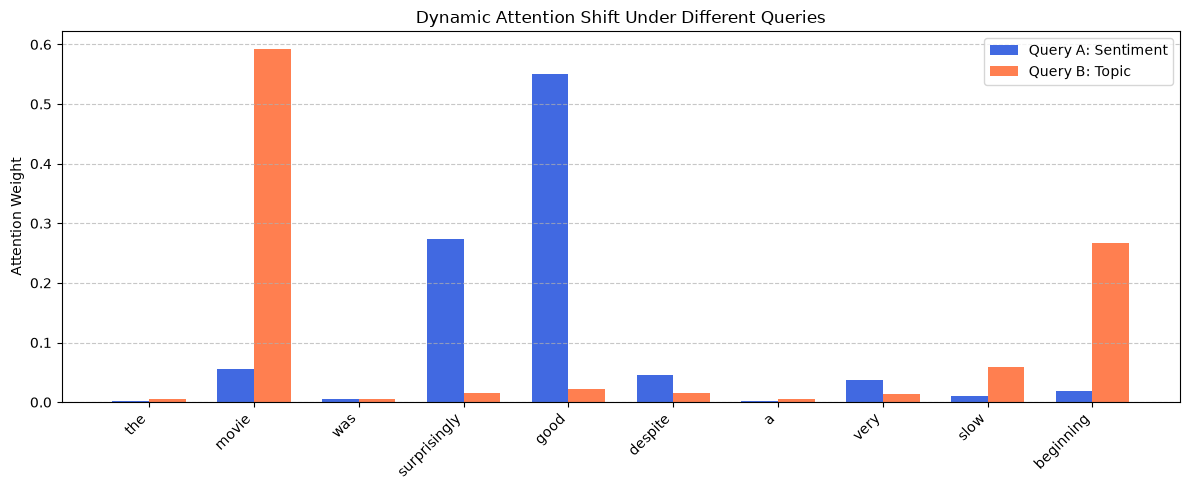

In [5]:
sentiment_scores = np.array([word_scores.get(t, 0.0) for t in tokens])

topic_scores_dict = {
    'movie': 3.8,
    'beginning': 3.0,
    'slow': 1.5,
    'the': -1.0,
    'was': -1.0,
    'surprisingly': 0.2,
    'good': 0.5,
    'despite': 0.2,
    'a': -1.0,
    'very': 0.0
}
topic_scores = np.array([topic_scores_dict.get(t, 0.0) for t in tokens])

weights_sentiment = stable_softmax(sentiment_scores)
weights_topic = stable_softmax(topic_scores)

query_df = pd.DataFrame({
    'Token': tokens,
    'Weight_Query_Sentiment': np.round(weights_sentiment, 4),
    'Weight_Query_Topic': np.round(weights_topic, 4)
})
print("Comparison Between Query A (Sentiment) and Query B (Topic):")
print(query_df)

plt.figure(figsize=(12, 5))
x_indices = np.arange(len(tokens))
bar_width = 0.35
plt.bar(x_indices - bar_width/2, weights_sentiment, width=bar_width, label='Query A: Sentiment', color='royalblue')
plt.bar(x_indices + bar_width/2, weights_topic, width=bar_width, label='Query B: Topic', color='coral')
plt.xticks(x_indices, tokens, rotation=45, ha='right')
plt.ylabel('Attention Weight')
plt.title('Dynamic Attention Shift Under Different Queries')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 6. Experiment 3: Trực quan hóa ma trận Self-Attention (Heatmap)

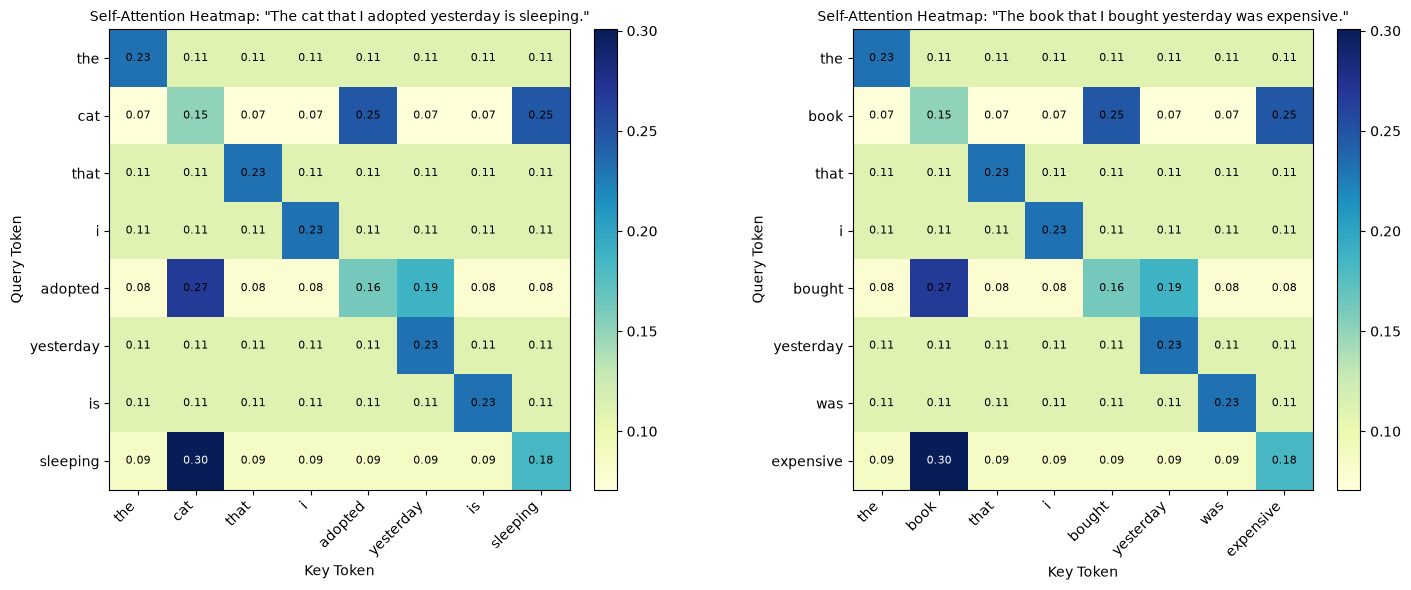

In [6]:
demo_sentences = [
    "The cat that I adopted yesterday is sleeping.",
    "The book that I bought yesterday was expensive."
]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for idx, sent in enumerate(demo_sentences):
    sent_tokens = re.findall(r'\b\w+\b', sent.lower())
    num_tokens = len(sent_tokens)
    raw_interactions = np.zeros((num_tokens, num_tokens))
    
    for r, t_r in enumerate(sent_tokens):
        for c, t_c in enumerate(sent_tokens):
            if t_r == t_c:
                raw_interactions[r, c] += 1.5
            if (t_r, t_c) in [('cat', 'sleeping'), ('sleeping', 'cat'), ('cat', 'adopted'), ('adopted', 'cat')]:
                raw_interactions[r, c] += 2.5
            if (t_r, t_c) in [('book', 'expensive'), ('expensive', 'book'), ('book', 'bought'), ('bought', 'book')]:
                raw_interactions[r, c] += 2.5
            if (t_r, t_c) in [('adopted', 'yesterday'), ('bought', 'yesterday')]:
                raw_interactions[r, c] += 1.8
                
    attention_matrix = stable_softmax(raw_interactions / np.sqrt(4.0), axis=-1)
    
    im = axes[idx].imshow(attention_matrix, cmap='YlGnBu')
    axes[idx].set_xticks(range(num_tokens))
    axes[idx].set_yticks(range(num_tokens))
    axes[idx].set_xticklabels(sent_tokens, rotation=45, ha='right')
    axes[idx].set_yticklabels(sent_tokens)
    
    for r in range(num_tokens):
        for c in range(num_tokens):
            val = attention_matrix[r, c]
            axes[idx].text(c, r, f"{val:.2f}", ha='center', va='center', color='black' if val < 0.3 else 'white', fontsize=8)
            
    axes[idx].set_title(f'Self-Attention Heatmap: "{sent}"', fontsize=10)
    axes[idx].set_xlabel('Key Token')
    axes[idx].set_ylabel('Query Token')
    fig.colorbar(im, ax=axes[idx], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig('attention_heatmap.png', dpi=300)
plt.show()

## 7. Experiment 4: Huấn luyện Self-Attention Classifier trên IMDb

In [7]:
dataset_file = '../Lab5/dataset/IMDB Dataset.csv'
if not os.path.exists(dataset_file):
    dataset_file = 'd:/Hus/NLP/Lab5/dataset/IMDB Dataset.csv'

dataframe = pd.read_csv(dataset_file)
dataframe['clean_text'] = dataframe['review'].apply(lambda s: re.sub(r'<[^>]+>', ' ', s).lower().strip())
dataframe['label'] = dataframe['sentiment'].map({'positive': 1, 'negative': 0})

sample_dataframe = dataframe.sample(n=10000, random_state=42).reset_index(drop=True)
train_df, test_df = train_test_split(sample_dataframe, test_size=0.3, random_state=42, stratify=sample_dataframe['label'])
val_df, test_df = train_test_split(test_df, test_size=0.5, random_state=42, stratify=test_df['label'])

token_counts = Counter()
for text in train_df['clean_text']:
    token_counts.update(re.findall(r'\b\w+\b', text))

vocab = {'<PAD>': 0, '<UNK>': 1}
for word, _ in token_counts.most_common(9998):
    vocab[word] = len(vocab)

def tokenize_and_pad(text, max_len=100):
    words = re.findall(r'\b\w+\b', text.lower())
    indices = [vocab.get(w, vocab['<UNK>']) for w in words[:max_len]]
    if len(indices) < max_len:
        indices += [vocab['<PAD>']] * (max_len - len(indices))
    return indices

class IMDbDataset(Dataset):
    def __init__(self, texts, labels, max_len=100):
        self.texts = texts.tolist()
        self.labels = labels.tolist()
        self.max_len = max_len
        
    def __len__(self):
        return len(self.texts)
        
    def __getitem__(self, idx):
        seq = tokenize_and_pad(self.texts[idx], self.max_len)
        return torch.tensor(seq, dtype=torch.long), torch.tensor(self.labels[idx], dtype=torch.float32)

train_loader = DataLoader(IMDbDataset(train_df['clean_text'], train_df['label']), batch_size=64, shuffle=True)
val_loader = DataLoader(IMDbDataset(val_df['clean_text'], val_df['label']), batch_size=64, shuffle=False)
test_loader = DataLoader(IMDbDataset(test_df['clean_text'], test_df['label']), batch_size=64, shuffle=False)

class SelfAttentionClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.w_q = nn.Linear(embed_dim, hidden_dim, bias=False)
        self.w_k = nn.Linear(embed_dim, hidden_dim, bias=False)
        self.w_v = nn.Linear(embed_dim, hidden_dim, bias=False)
        self.scale = np.sqrt(hidden_dim)
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()
        
    def forward(self, x):
        emb = self.embedding(x)
        Q = self.w_q(emb)
        K = self.w_k(emb)
        V = self.w_v(emb)
        scores = torch.bmm(Q, K.transpose(1, 2)) / self.scale
        attention_weights = torch.softmax(scores, dim=-1)
        context = torch.bmm(attention_weights, V)
        pooled = torch.mean(context, dim=1)
        logits = self.fc(pooled).squeeze(-1)
        return self.sigmoid(logits), attention_weights

model = SelfAttentionClassifier(len(vocab), embed_dim=64, hidden_dim=64)
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

total_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable Parameters: {total_parameters}")

start_training_time = time.time()
for epoch in range(5):
    model.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        optimizer.zero_grad()
        probs, _ = model(inputs)
        loss = criterion(probs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    print(f"Epoch {epoch+1}/5 - Loss: {running_loss/len(train_loader):.4f}")
total_time = time.time() - start_training_time
print(f"Training completed in {total_time:.2f} seconds.")

Trainable Parameters: 652353


Epoch 1/5 - Loss: 0.6672


Epoch 2/5 - Loss: 0.5802


Epoch 3/5 - Loss: 0.4884


Epoch 4/5 - Loss: 0.4100


Epoch 5/5 - Loss: 0.3442
Training completed in 8.22 seconds.


## 8. Đánh giá định lượng và xuất kết quả results.csv, confusion_matrix.png

Test Accuracy: 0.7633
Test Precision: 0.7614
Test Recall: 0.7725
Test F1: 0.7669


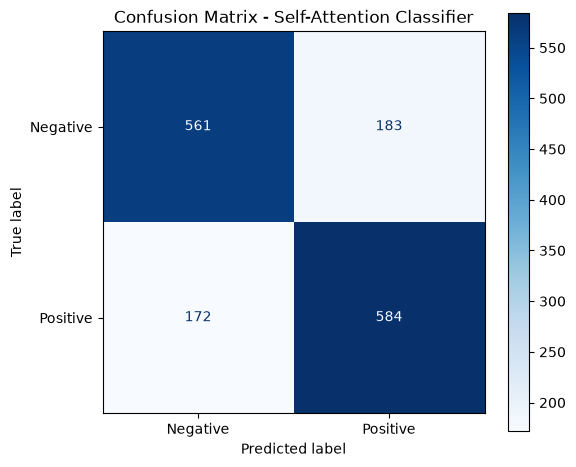

Updated results.csv successfully.


In [8]:
model.eval()
test_predictions = []
test_targets = []

with torch.no_grad():
    for inputs, labels in test_loader:
        probs, _ = model(inputs)
        test_predictions.extend((probs >= 0.5).long().cpu().numpy())
        test_targets.extend(labels.cpu().numpy())

accuracy = accuracy_score(test_targets, test_predictions)
precision = precision_score(test_targets, test_predictions)
recall = recall_score(test_targets, test_predictions)
f1 = f1_score(test_targets, test_predictions)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1: {f1:.4f}")

cm = confusion_matrix(test_targets, test_predictions)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative', 'Positive'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Confusion Matrix - Self-Attention Classifier')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300)
plt.show()

summary_records = [
    {
        'Model': 'Logistic Regression',
        'Representation': 'TF-IDF (10k features)',
        'Sequence_Length': 'All',
        'Parameters': 10001,
        'Training_Time_s': 1.33,
        'Accuracy': 0.8700,
        'Precision': 0.8537,
        'Recall': 0.8955,
        'F1': 0.8741
    },
    {
        'Model': 'Simple RNN',
        'Representation': 'Embedding (d=64)',
        'Sequence_Length': 100,
        'Parameters': 648450,
        'Training_Time_s': 13.47,
        'Accuracy': 0.4920,
        'Precision': 0.4956,
        'Recall': 0.4458,
        'F1': 0.4694
    },
    {
        'Model': 'LSTM',
        'Representation': 'Embedding (d=64)',
        'Sequence_Length': 100,
        'Parameters': 673410,
        'Training_Time_s': 11.00,
        'Accuracy': 0.5220,
        'Precision': 0.5271,
        'Recall': 0.5013,
        'F1': 0.5139
    },
    {
        'Model': 'GRU',
        'Representation': 'Embedding (d=64)',
        'Sequence_Length': 100,
        'Parameters': 665090,
        'Training_Time_s': 32.75,
        'Accuracy': 0.6667,
        'Precision': 0.6711,
        'Recall': 0.6640,
        'F1': 0.6676
    },
    {
        'Model': 'Self-Attention',
        'Representation': 'Embedding (d=64)',
        'Sequence_Length': 100,
        'Parameters': total_parameters,
        'Training_Time_s': round(total_time, 2),
        'Accuracy': round(accuracy, 4),
        'Precision': round(precision, 4),
        'Recall': round(recall, 4),
        'F1': round(f1, 4)
    }
]

pd.DataFrame(summary_records).to_csv('results.csv', index=False)
print("Updated results.csv successfully.")

## 9. Ứng dụng: Dự đoán và phân tích Attention trên các câu mẫu

In [9]:
test_sentences = [
    "I like this movie.",
    "I do not like this movie.",
    "I thought this movie would be bad, but it was actually excellent."
]

for sent in test_sentences:
    words = re.findall(r'\b\w+\b', sent.lower())
    indices = [vocab.get(w, vocab['<UNK>']) for w in words]
    tensor_input = torch.tensor([indices], dtype=torch.long)
    with torch.no_grad():
        prob, attn = model(tensor_input)
    pred_label = "Positive" if prob.item() >= 0.5 else "Negative"
    print(f"\nSentence: \"{sent}\"")
    print(f"Predicted: {pred_label} (Probability: {prob.item():.4f})")
    
    avg_attn_weights = attn[0].mean(dim=0).cpu().numpy()
    top_indices = np.argsort(avg_attn_weights)[::-1]
    top_tokens = [(words[idx], round(float(avg_attn_weights[idx]), 4)) for idx in top_indices[:3]]
    print(f"Top 3 Attended Tokens: {top_tokens}")


Sentence: "I like this movie."
Predicted: Negative (Probability: 0.0000)
Top 3 Attended Tokens: [('i', 0.3737), ('this', 0.2258), ('like', 0.2125)]

Sentence: "I do not like this movie."
Predicted: Negative (Probability: 0.0000)
Top 3 Attended Tokens: [('i', 0.2372), ('do', 0.234), ('not', 0.1882)]

Sentence: "I thought this movie would be bad, but it was actually excellent."
Predicted: Negative (Probability: 0.0164)
Top 3 Attended Tokens: [('bad', 0.2704), ('this', 0.1215), ('would', 0.115)]


## 10. Experiment 5: Phân tích độ phức tạp O(T^2) theo chiều dài chuỗi

Computational Cost Analysis Table:
   Sequence_Length Attention_Matrix_Size  Total_Elements  Memory_MB
0               10                 10x10             100     0.0004
1              100               100x100           10000     0.0381
2              500               500x500          250000     0.9537
3             1000             1000x1000         1000000     3.8147
4             2000             2000x2000         4000000    15.2588
5            10000           10000x10000       100000000   381.4697


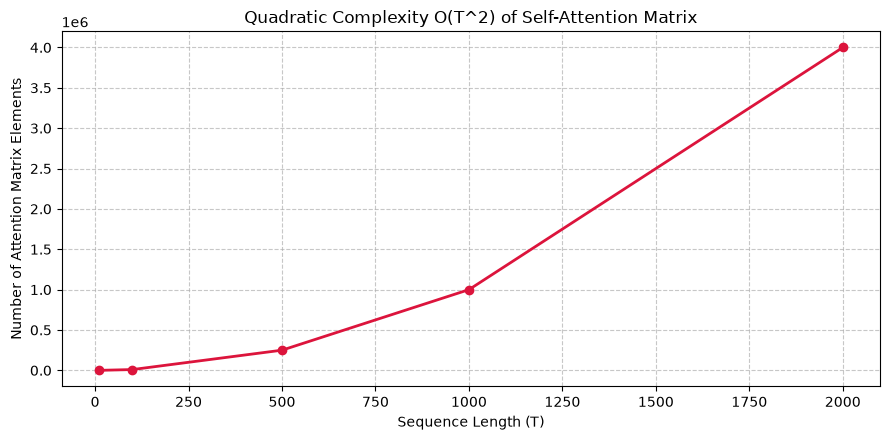

In [10]:
seq_lengths = [10, 100, 500, 1000, 2000, 10000]
cost_records = []

for length in seq_lengths:
    num_elements = length * length
    mem_bytes = num_elements * 4
    mem_mb = mem_bytes / (1024 * 1024)
    cost_records.append({
        'Sequence_Length': length,
        'Attention_Matrix_Size': f"{length}x{length}",
        'Total_Elements': num_elements,
        'Memory_MB': round(mem_mb, 4)
    })

cost_df = pd.DataFrame(cost_records)
print("Computational Cost Analysis Table:")
print(cost_df)

plt.figure(figsize=(9, 4.5))
plt.plot(seq_lengths[:5], [r['Total_Elements'] for r in cost_records[:5]], marker='o', color='crimson', linewidth=2)
plt.xlabel('Sequence Length (T)')
plt.ylabel('Number of Attention Matrix Elements')
plt.title('Quadratic Complexity O(T^2) of Self-Attention Matrix')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()